# 07 · Predicting molecular subtype from tissue architecture

Can the interpretable tissue features of OpenTME predict the molecular subtype of a tumour, which is defined from gene expression and cannot be read directly from an H&E slide? And which features does a model rely on to do so?

Structure:
1. **Data and image features**, the same selection as notebook 06.
2. **Evaluation design:** whole tissue source sites held out for a single final test, site-grouped cross-validation for every decision, preprocessing learned inside each training fold.
3. **Subtype prediction:** baseline, overfitting and regularisation, comparison of four model families, selection of the simplest equivalent model, performance by subtype, SHAP explanation and final evaluation on the held-out sites.

The prediction of genomic alterations is explored separately, as a preliminary extension, in notebook 08.

Parameters are in `configs/analysis.yaml` (section `genomic_prediction`) and in the indication file; reusable functions are in `src/opentme_tcga/genomic_prediction.py`. The *Observations* describe the results of the pilot indication (breast cancer, PAM50 subtypes).

**Outputs**: tables in `results/<indication>/07_subtype_prediction/` and figures in `figures/<indication>/07_subtype_prediction/`.

## 0. Setup

In [4]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import shap
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report, f1_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, RandomizedSearchCV, cross_val_predict,
                                     cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from opentme_tcga import genomic_prediction as gp
from opentme_tcga import phenotypes as ph
from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.genomic_footprints import select_image_features
from opentme_tcga.plotting import TLS_GROUP_COLORS, TLS_MATURITY_COLORS, category_colors

INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
GP = cfg["genomic_prediction"]
SUB = cfg["tcga_molecular"]["subtypes"]

OUT_DIR = P["results"] / "07_subtype_prediction"
FIGS = P["figures"] / "07_subtype_prediction"
ensure_dirs(cfg)
FIGS.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Known, harmless FutureWarnings (e.g. SVC(probability=True)), also in the parallel workers
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"

## 1. Configuration

Column names and settings come from the configuration; here they only get short names.

In [5]:
SUBTYPE, SUBTYPE_LABEL = SUB["column"], SUB["label"]
GROUP = GP["group_column"]
SEED = GP["seed"]
cv = GroupKFold(n_splits=GP["cv_folds"])       # every fold contains whole sites

## 2. Data and image features

### 2.1 Integrated table

One row per patient (notebook 03). A tumour mutational burden of 0 in a tumour without mutation calls is missing data, not a true absence of mutations, so it is set to missing.

In [6]:
data = pd.read_parquet(P["integrated"])
print(f"Patients: {len(data)} | columns: {data.shape[1]}")

if {"thor_tmb", "mut_profiled"} <= set(data.columns):
    false_zero = (data["thor_tmb"] == 0) & (data["mut_profiled"] != 1)
    data.loc[false_zero, "thor_tmb"] = np.nan
    print(f"TMB set to missing in {false_zero.sum()} tumours without mutation calls")

Patients: 1025 | columns: 756
TMB set to missing in 51 tumours without mutation calls


### 2.2 Image features

The same selection as notebook 06 (`genomic_footprints.image`): absolute counts and areas, which mainly reflect the amount of tissue on the slide, quality-control readouts, features with more than 20 % missing values and near-constant features are removed. `extra_drop_columns` removes a few more for prediction (presence of any TLS, found in most tumours and already described by the TLS densities). Features measured inside vessels were removed in notebook 01.

In [7]:
IMG = cfg["genomic_footprints"]["image"]
opentme_columns = pq.read_schema(P["opentme_patients"]).names
image_features = select_image_features(
    data, opentme_columns, drop_prefixes=IMG["drop_prefixes"], drop_substrings=IMG["drop_substrings"],
    drop_columns=IMG["drop_columns"] + GP["extra_drop_columns"], max_missing=IMG["max_missing"],
    max_dominant_fraction=IMG["max_dominant_fraction"],
)
print(f"Image features: {len(image_features)} of {len(opentme_columns)} OpenTME columns")

Image features: 379 of 647 OpenTME columns


## 3. Evaluation design

The choices in this section apply to every prediction task in the notebook.

### 3.1 Held-out sites

Each tissue source site processes, stains and scans slides in its own way, so image features carry a site-specific signature. If patients from the same site appeared in both training and test data, a model could exploit it and its performance would be overestimated. Entire sites are therefore held out: the test set contains only sites never used for training, feature selection or model selection, and it is used once, at the end. The test sites are drawn once (among patients with a known `split_column`; breast: TP53 status) and shared with notebook 08.

In [8]:
split_column = GP["split_column"] or SUBTYPE
split_data = data.dropna(subset=[split_column, GROUP])
test_sites = gp.site_split(split_data, GROUP, GP["test_size"], SEED)
is_test = data[GROUP].isin(test_sites)

print(f"Train: {(~is_test).sum()} patients from {data.loc[~is_test, GROUP].nunique()} sites")
print(f"Test:  {is_test.sum()} patients from {len(test_sites)} sites")

Train: 731 patients from 30 sites
Test:  294 patients from 8 sites


### 3.2 Redundancy among image features

OpenTME describes tissue architecture with many closely related measurements: the same quantity at several radii, in several tissue regions, or as a density, a ratio or an average. Strongly correlated features add dimensions without adding information and increase the risk of overfitting. Near-duplicates are removed using Spearman correlations on the training patients only: features are visited from fewest to most missing values, and a feature is kept only if its absolute correlation with every feature already kept is at most the threshold, so from each group the most complete feature is retained. No target is used.

In [9]:
train_all = data[~is_test]
for t in GP["redundancy_thresholds"]:
    print(f"|rho| > {t}: {len(gp.drop_redundant(train_all, image_features, t))} features remain")

FEATURES = gp.drop_redundant(train_all, image_features, GP["redundancy_threshold"])
print(f"\nImage features used (|rho| <= {GP['redundancy_threshold']}): {len(FEATURES)}")

|rho| > 0.95: 343 features remain
|rho| > 0.9: 275 features remain
|rho| > 0.8: 184 features remain

Image features used (|rho| <= 0.9): 275


### 3.3 Preprocessing, cross-validation and metrics

- **Preprocessing** is part of every model pipeline, so imputation values, transformations and encodings are learned from the training data of each fold only. Numeric features are imputed with the median and mapped to a normal distribution by ranks (as in notebook 06); missing categories (e.g. subtype in the clinical baseline) become their own level instead of being guessed.
- **Cross-validation:** every decision (model, hyperparameters, feature set) is taken by five-fold cross-validation grouped by site within the training sites.
- **Metrics:** ROC-AUC, which does not depend on a decision threshold and equals 0.5 without information (one-vs-rest for several classes); F1, classification reports and confusion matrices describe the default decision rule. Accuracy is only reported against a dummy classifier, because with imbalanced classes a high accuracy can be reached without learning anything. Class imbalance is handled by weighting patients inversely to their class frequency.

In [10]:
preprocessor = gp.make_preprocessor()

## 4. Subtype prediction

Molecular subtypes are defined from gene expression and are approximated in practice by immunohistochemistry; they cannot be read directly from an H&E slide, but they differ in grade, proliferation and immune infiltration.

### 4.1 Subtypes and data split

The classes are set in `classes` (breast: the four tumour subtypes; normal-like is excluded because it is small and often reflects samples rich in normal breast tissue).

In [11]:
counts = data[SUBTYPE].value_counts()
CLASSES = GP["classes"] or counts[counts >= GP["min_class_size"]].index.tolist()
display(counts.rename("patients").to_frame())

d_sub = data[data[SUBTYPE].isin(CLASSES)]
sub_train, sub_test = d_sub[~d_sub[GROUP].isin(test_sites)], d_sub[d_sub[GROUP].isin(test_sites)]
print(f"Train: {len(sub_train)} patients, test: {len(sub_test)} patients")
display(pd.crosstab(d_sub[SUBTYPE], d_sub[GROUP].isin(test_sites).map({False: "train", True: "test"})).loc[CLASSES])

X_train, y_train, g_train = sub_train[FEATURES], sub_train[SUBTYPE], sub_train[GROUP]
encoder = LabelEncoder().fit(CLASSES)                      # numeric labels (required by XGBoost)
y_train_num = encoder.transform(y_train)
weights = compute_sample_weight("balanced", y_train_num)   # balanced patient weights, all models
COLORS = category_colors(CLASSES, SUB.get("colors"))

,patients
clin_pam50,
LumA,521
LumB,214
Basal,176
HER2E,77
normal-like,35


Train: 701 patients, test: 287 patients


clin_tss,test,train
clin_pam50,,
LumA,171,350
LumB,45,169
Basal,51,125
HER2E,20,57


### 4.2 Baseline

A dummy classifier that ignores the image and always predicts the most frequent subtype sets the reference level; a class-balanced logistic regression on the image features is the first model. Summary metrics come from the five folds; the classification report and the confusion matrix from out-of-fold predictions.

=== dummy ===
ROC-AUC 0.50 ± 0.00   F1 macro 0.17 ± 0.01   accuracy 0.50

              precision    recall  f1-score   support

        LumA       0.50      1.00      0.67       350
        LumB       0.00      0.00      0.00       169
       Basal       0.00      0.00      0.00       125
       HER2E       0.00      0.00      0.00        57

    accuracy                           0.50       701
   macro avg       0.12      0.25      0.17       701
weighted avg       0.25      0.50      0.33       701

=== logistic ===
ROC-AUC 0.81 ± 0.02   F1 macro 0.55 ± 0.01   accuracy 0.61

              precision    recall  f1-score   support

        LumA       0.79      0.67      0.73       350
        LumB       0.42      0.50      0.46       169
       Basal       0.67      0.70      0.69       125
       HER2E       0.30      0.37      0.33        57

    accuracy                           0.61       701
   macro avg       0.54      0.56      0.55       701
weighted avg       0.64      0.61 

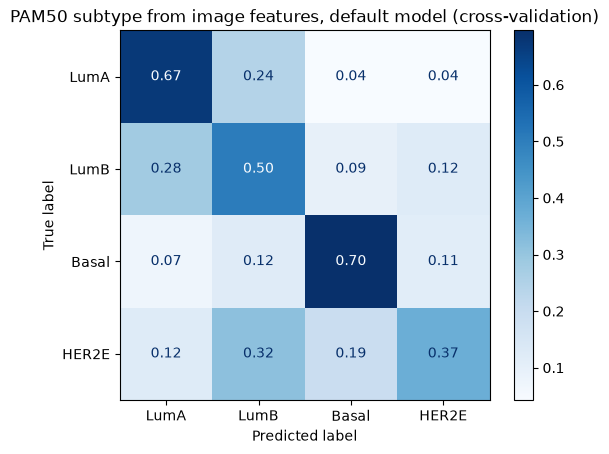

In [12]:
baselines = {"dummy": DummyClassifier(strategy="most_frequent"),
             "logistic": LogisticRegression(class_weight="balanced", max_iter=5000)}
for name, model in baselines.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
    scores = cross_validate(pipeline, X_train, y_train, groups=g_train, cv=cv,
                            scoring=["roc_auc_ovr", "f1_macro", "accuracy"])
    print(f"=== {name} ===")
    print(f"ROC-AUC {scores['test_roc_auc_ovr'].mean():.2f} ± {scores['test_roc_auc_ovr'].std():.2f}   "
          f"F1 macro {scores['test_f1_macro'].mean():.2f} ± {scores['test_f1_macro'].std():.2f}   "
          f"accuracy {scores['test_accuracy'].mean():.2f}\n")
    y_pred = cross_val_predict(pipeline, X_train, y_train, groups=g_train, cv=cv)
    print(classification_report(y_train, y_pred, labels=CLASSES, zero_division=0))

# Where the default logistic regression errs (rows: true subtype, each row sums to 1)
disp = ConfusionMatrixDisplay.from_predictions(y_train, y_pred, labels=CLASSES, normalize="true",
                                               values_format=".2f", cmap="Blues")
disp.ax_.set_title(f"{SUBTYPE_LABEL} from image features, default model (cross-validation)")
disp.figure_.savefig(FIGS / "subtype_cv_confusion_default.png", bbox_inches="tight")
plt.show()

**Observations (breast)**
- Image features carry clear information on subtype: the default logistic regression outperforms the dummy classifier on every metric.
- The information is uneven across subtypes: basal-like and luminal A are recognised best; luminal A and B are often confused, consistent with their separation along a proliferation continuum; HER2-enriched tumours are spread across the other subtypes. Part of these errors may reflect overfitting (section 4.3).

### 4.3 Overfitting, regularisation and feature selection

With several hundred image features and a few hundred patients per training fold, a logistic regression with the default regularisation may overfit. A **validation curve** compares, for each inverse penalty `C` (smaller = stronger L2 regularisation), the AUC on the training folds with the AUC on the validation folds.

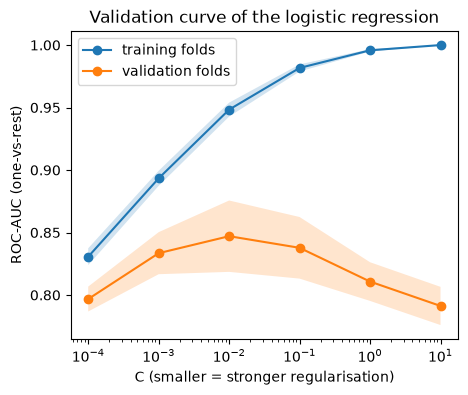

,C,train_auc,validation_auc,gap
0,0.000,0.831,0.797,0.034
1,0.001,0.893,0.833,0.060
2,0.010,0.948,0.847,0.101
3,0.100,0.982,0.838,0.144
4,1.000,0.996,0.811,0.185
5,10.000,1.000,0.791,0.209


In [13]:
logistic = Pipeline([("preprocess", preprocessor),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])
C_range = GP["validation_C"]
train_scores, val_scores = validation_curve(logistic, X_train, y_train, param_name="model__C",
                                            param_range=C_range, groups=g_train, cv=cv,
                                            scoring="roc_auc_ovr", n_jobs=-1)

fig, ax = plt.subplots(figsize=(5, 4))
for scores, label in [(train_scores, "training folds"), (val_scores, "validation folds")]:
    mean, sd = scores.mean(axis=1), scores.std(axis=1)
    ax.semilogx(C_range, mean, marker="o", label=label)
    ax.fill_between(C_range, mean - sd, mean + sd, alpha=0.2)
ax.set_xlabel("C (smaller = stronger regularisation)")
ax.set_ylabel("ROC-AUC (one-vs-rest)")
ax.set_title("Validation curve of the logistic regression")
ax.legend()
fig.savefig(FIGS / "subtype_validation_curve.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame({"C": C_range, "train_auc": train_scores.mean(axis=1), "validation_auc": val_scores.mean(axis=1),
                      "gap": train_scores.mean(axis=1) - val_scores.mean(axis=1)}).round(3))

**Observations (breast)**
- With the default regularisation (C = 1) and weaker, the training patients are separated almost perfectly while performance on unseen sites declines: overfitting. With very strong regularisation both curves drop (underfitting). Validation performance peaks around C = 0.01; a gap remains, as expected with nearly as many features as patients.

An alternative to stronger regularisation is to keep fewer features: `C` is tuned jointly with a univariate selection step that keeps the `k` features with the largest ANOVA F statistic between subtypes, fitted within each training fold.

In [14]:
select_pipeline = Pipeline([("preprocess", preprocessor), ("select", SelectKBest(score_func=f_classif)),
                            ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])
grid = GridSearchCV(select_pipeline, GP["selection_grid"], cv=cv, scoring=["roc_auc_ovr", "f1_macro"],
                    refit="roc_auc_ovr", n_jobs=-1)
grid.fit(X_train, y_train, groups=g_train)
columns = ["param_select__k", "param_model__C", "mean_test_roc_auc_ovr", "std_test_roc_auc_ovr", "mean_test_f1_macro"]
display(pd.DataFrame(grid.cv_results_)[columns].sort_values("mean_test_roc_auc_ovr", ascending=False).head(10).round(3))
print(f"Best combination: {grid.best_params_}")

,param_select__k,param_model__C,mean_test_roc_auc_ovr,std_test_roc_auc_ovr,mean_test_f1_macro
8,200,0.010,0.847,0.027,0.570
9,all,0.010,0.847,0.029,0.572
13,200,0.100,0.843,0.026,0.570
12,100,0.100,0.842,0.034,0.563
7,100,0.010,0.840,0.024,0.551
14,all,0.100,0.838,0.025,0.559
4,all,0.001,0.833,0.017,0.537
3,200,0.001,0.831,0.016,0.540
17,100,1.000,0.820,0.035,0.533
11,50,0.100,0.819,0.037,0.520


Best combination: {'model__C': 0.01, 'select__k': 200}


**Observations (breast)**
- The best combinations keep 200 or all image features with C = 0.01 (AUC 0.847 both); fewer features perform worse. Feature selection does not improve on regularisation: the signal is spread across many weakly informative, correlated features. All image features are kept from here on, and the regularisation of each model is tuned.

### 4.4 Comparison of model families

Four families: logistic regression, support vector machines, random forests and gradient boosting (XGBoost). Each is tuned by a randomised search (`n_iter` configurations) over a wide hyperparameter space fixed in the configuration before looking at the results (`search_spaces`), with the same site-grouped cross-validation and the same patient weights. Best values at the edge of their range are reported below; the ranges are not changed after seeing the results.

In [15]:
ESTIMATORS = {
    "logistic": LogisticRegression(max_iter=5000),
    "svm": SVC(probability=True, random_state=SEED),
    "random_forest": RandomForestClassifier(random_state=SEED, n_jobs=1),
    "xgboost": XGBClassifier(random_state=SEED, n_jobs=1),
}
rows, best_models, fold_auc, edges = [], {}, {}, []
for name in GP["complexity_order"]:
    space = gp.parse_space(GP["search_spaces"][name])
    search = RandomizedSearchCV(Pipeline([("preprocess", preprocessor), ("model", clone(ESTIMATORS[name]))]),
                                space, n_iter=GP["n_iter"], cv=cv, scoring=["roc_auc_ovr", "f1_macro"],
                                refit="roc_auc_ovr", random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train_num, groups=g_train, model__sample_weight=weights)
    best = search.best_index_
    rows.append({"model": name, "roc_auc_mean": search.cv_results_["mean_test_roc_auc_ovr"][best],
                 "roc_auc_sd": search.cv_results_["std_test_roc_auc_ovr"][best],
                 "f1_macro_mean": search.cv_results_["mean_test_f1_macro"][best], "best_params": search.best_params_})
    best_models[name] = search.best_estimator_                 # refitted on all training patients
    fold_auc[name] = gp.fold_scores(search, "roc_auc_ovr")
    edges.append(gp.edge_check(space, search.best_params_).assign(model=name))
    print(f"{name} done")

model_comparison = pd.DataFrame(rows)
model_comparison.to_csv(OUT_DIR / "subtype_model_comparison.csv", index=False)
display(model_comparison.round(3))
edges = pd.concat(edges, ignore_index=True)
print("Best values at the edge of their range (see the observations below):")
display(edges[edges["at_edge"]].round(3))

logistic done
svm done
random_forest done
xgboost done


,model,roc_auc_mean,roc_auc_sd,f1_macro_mean,best_params
0,logistic,0.847,0.028,0.573,{'model__C': 0.015876781526923997}
1,svm,0.857,0.029,0.574,"{'model__C': 78.52755494724258, 'model__gamma'..."
2,random_forest,0.836,0.017,0.534,"{'model__max_depth': 20, 'model__max_features'..."
3,xgboost,0.855,0.019,0.557,{'model__colsample_bytree': 0.4595546137793591...


Best values at the edge of their range (if any, the range should be widened):


,hyperparameter,best_value,range,position,at_edge,model
1,model__C,78.528,"[0.01, 100]",0.974,True,svm
4,model__min_samples_leaf,1.000,"[1, 19]",0.000,True,random_forest
11,model__reg_lambda,0.103,"[0.1, 10]",0.007,True,xgboost


**Observations (breast)**
- The four families perform within cross-validation variability of each other (AUC 0.84–0.86, SD across folds 0.02–0.03).
- Some best values lie at the edge of their range (SVM C at the upper end, XGBoost reg_lambda at the lower end, random-forest leaf size at its minimum possible value). Ranges were fixed in advance and are not widened: differences between families are smaller than between folds, so a gain large enough to change the selection (> 1 SD) is unlikely.
- Performance is limited by the image features, not by the algorithm or its tuning.

### 4.5 Model selection

The families are evaluated on the same folds, so they can be compared fold by fold. The rule was fixed before looking at the results: models whose mean AUC lies within one standard deviation (across folds) of the best model are equivalent, since such differences are smaller than the variability between sites, and among equivalent models the simplest and most interpretable one is selected (`complexity_order`). Interpretability matters because the selected model is explained with SHAP in section 4.8.

,logistic,svm,random_forest,xgboost
fold,,,,
0,0.877,0.891,0.863,0.886
1,0.824,0.828,0.815,0.836
2,0.884,0.894,0.849,0.867
3,0.834,0.838,0.827,0.852
4,0.816,0.834,0.827,0.835


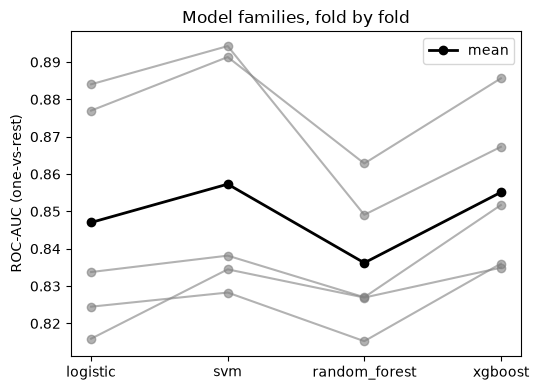

Best mean AUC: svm (0.857) | equivalence threshold: 0.828
Equivalent models: ['logistic', 'svm', 'random_forest', 'xgboost'] → selected: logistic


In [16]:
folds = pd.DataFrame(fold_auc).rename_axis("fold")
display(folds.round(3))
fig = gp.plot_folds(folds, "ROC-AUC (one-vs-rest)", "Model families, fold by fold")
fig.savefig(FIGS / "subtype_model_families_by_fold.png", bbox_inches="tight")
plt.show()

SELECTED, threshold, equivalent = gp.select_equivalent(folds, GP["complexity_order"])
print(f"Best mean AUC: {folds.mean().idxmax()} ({folds.mean().max():.3f}) | equivalence threshold: {threshold:.3f}")
print(f"Equivalent models: {equivalent} → selected: {SELECTED}")

**Observations (breast)**
- Differences between sites are much larger than differences between model families: fold-wise AUC ranges over ≈ 0.08, whereas the family means differ by ≈ 0.02 and their ranking changes from fold to fold.
- All four families are within one standard deviation of the best, so the regularised logistic regression is selected.

### 4.6 Selected model by subtype

Out-of-fold probabilities for every training patient give the one-vs-rest AUC of each subtype (how well the model ranks patients of that subtype above the others, regardless of the decision rule) and its ROC curve. The classification report and the confusion matrix describe the subtype assigned to each patient, the one with the highest probability.

,n_patients,roc_auc_vs_rest
subtype,,
LumA,350,0.880
LumB,169,0.770
Basal,125,0.922
HER2E,57,0.804


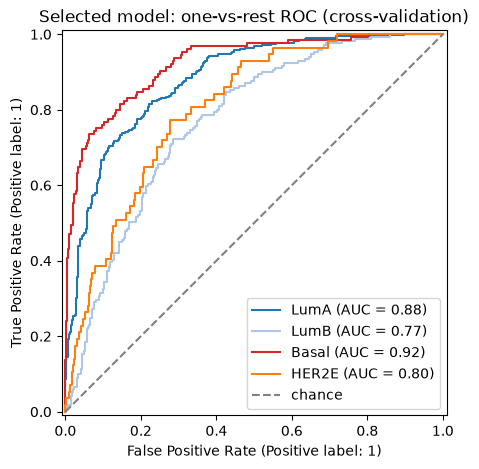

              precision    recall  f1-score   support

        LumA       0.83      0.69      0.76       350
        LumB       0.47      0.54      0.50       169
       Basal       0.68      0.71      0.70       125
       HER2E       0.30      0.46      0.36        57

    accuracy                           0.64       701
   macro avg       0.57      0.60      0.58       701
weighted avg       0.68      0.64      0.65       701



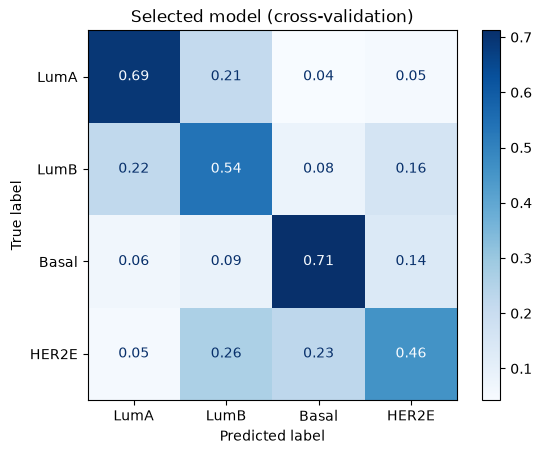

In [17]:
model = clone(best_models[SELECTED])
prob_oof = cross_val_predict(model, X_train, y_train_num, groups=g_train, cv=cv, method="predict_proba",
                             params={"model__sample_weight": weights})
pred_oof = encoder.inverse_transform(prob_oof.argmax(axis=1))

auc_by_subtype = pd.DataFrame([
    {"subtype": s, "n_patients": int((y_train == s).sum()),
     "roc_auc_vs_rest": roc_auc_score(y_train == s, prob_oof[:, list(encoder.classes_).index(s)])}
    for s in CLASSES]).set_index("subtype")
auc_by_subtype.to_csv(OUT_DIR / "subtype_cv_auc_by_subtype.csv")
display(auc_by_subtype.round(3))

fig, ax = plt.subplots(figsize=(5, 5))
for s in CLASSES:
    RocCurveDisplay.from_predictions(y_train == s, prob_oof[:, list(encoder.classes_).index(s)], name=s, ax=ax,
                                     curve_kwargs={"color": COLORS[s]})
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="chance")
ax.set_title("Selected model: one-vs-rest ROC (cross-validation)")
ax.legend(loc="lower right")
fig.savefig(FIGS / "subtype_cv_roc_by_subtype.png", bbox_inches="tight")
plt.show()

print(classification_report(y_train, pred_oof, labels=CLASSES, zero_division=0))
disp = ConfusionMatrixDisplay.from_predictions(y_train, pred_oof, labels=CLASSES, normalize="true",
                                               values_format=".2f", cmap="Blues")
disp.ax_.set_title("Selected model (cross-validation)")
disp.figure_.savefig(FIGS / "subtype_cv_confusion_selected.png", bbox_inches="tight")
plt.show()

**Observations (breast)**
- Compared with the default model, the selected model improves the ranking of patients (AUC 0.81 → 0.85) more than the assignment of a single subtype (macro F1 0.55 → 0.58); recall improves mainly for HER2-enriched tumours (0.37 → 0.46).

### 4.7 Sensitivity: vessel tissue features

Notebook 01 removed the features measured *inside* vessels, but kept vessel tissue itself (area, shape) and distances to vessels. To check that these remaining vessel-related features do not drive the result, the selected model is evaluated again without every feature whose name contains one of `sensitivity_drop_substrings`, on the same folds.

In [18]:
dropped = [f for f in FEATURES if any(s in f for s in GP["sensitivity_drop_substrings"])]
kept = [f for f in FEATURES if f not in dropped]
print(f"Features removed for the check: {len(dropped)}")
print(dropped)

sensitivity = pd.DataFrame({
    "all features": folds[SELECTED],
    "without these features": cross_validate(
        clone(best_models[SELECTED]), X_train[kept], y_train_num, groups=g_train, cv=cv, scoring="roc_auc_ovr",
        params={"model__sample_weight": weights})["test_score"],
}).rename_axis("fold")
display(sensitivity.round(3))
print(f"Mean AUC: {sensitivity.mean().round(3).to_dict()} | "
      f"mean difference {(sensitivity.iloc[:, 1] - sensitivity.iloc[:, 0]).mean():+.3f}")

Features removed for the check: 4
['RELATIVE_AREA_VESSEL', 'AVG_ECCENTRICITY_VESSEL', 'AVG_EXTENT_VESSEL', 'AVG_SOLIDICITY_VESSEL']


,all features,without these features
fold,,
0,0.877,0.876
1,0.824,0.824
2,0.884,0.882
3,0.834,0.836
4,0.816,0.814


Mean AUC: {'all features': 0.847, 'without these features': 0.846} | mean difference -0.001


**Observations (breast)**
- Removing the four vessel tissue features changes the cross-validated AUC by −0.001 (0.847 vs 0.846): they do not drive the result.

### 4.8 Which tissue features distinguish the subtypes?

SHAP values decompose each prediction into contributions of individual features. For a multinomial logistic regression they are exact and computed separately for each subtype: a positive value means the feature raises the probability of that subtype for that patient. They are computed for the tuned logistic regression (the selected model; if another family were selected, the logistic regression is still the one explained) on all training patients, using all of them as reference. Because regularisation spreads the weight across many correlated features, a single feature should be read as a representative of its correlated group.

Three figures:
- the most important features, with bars stacked by subtype (`shap_top_stacked`);
- per subtype, the most important features and the direction of their effect (`shap_top_signed`);
- two subtypes side by side (`shap_pair`; breast: luminal A vs basal-like).

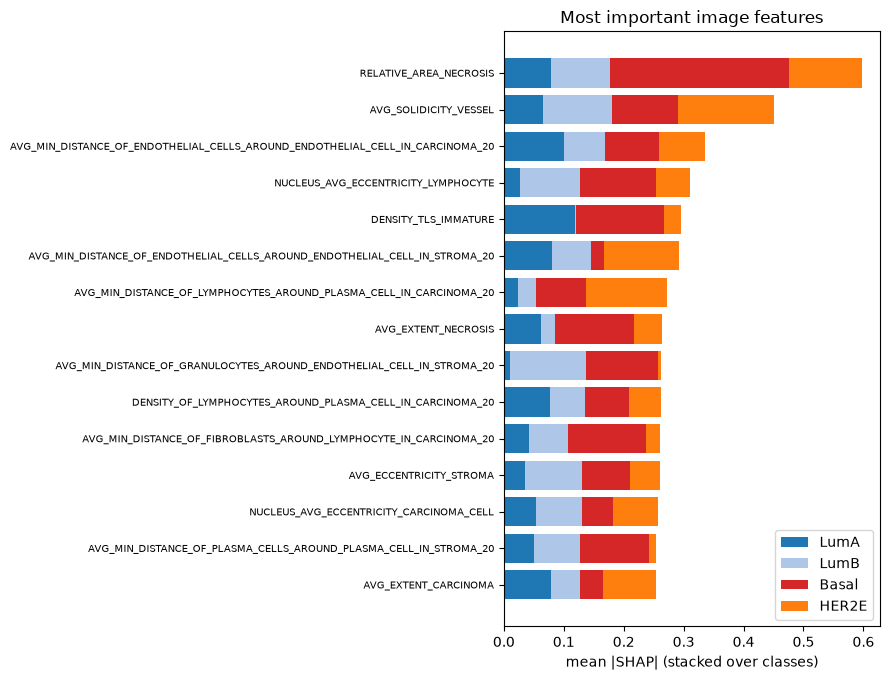

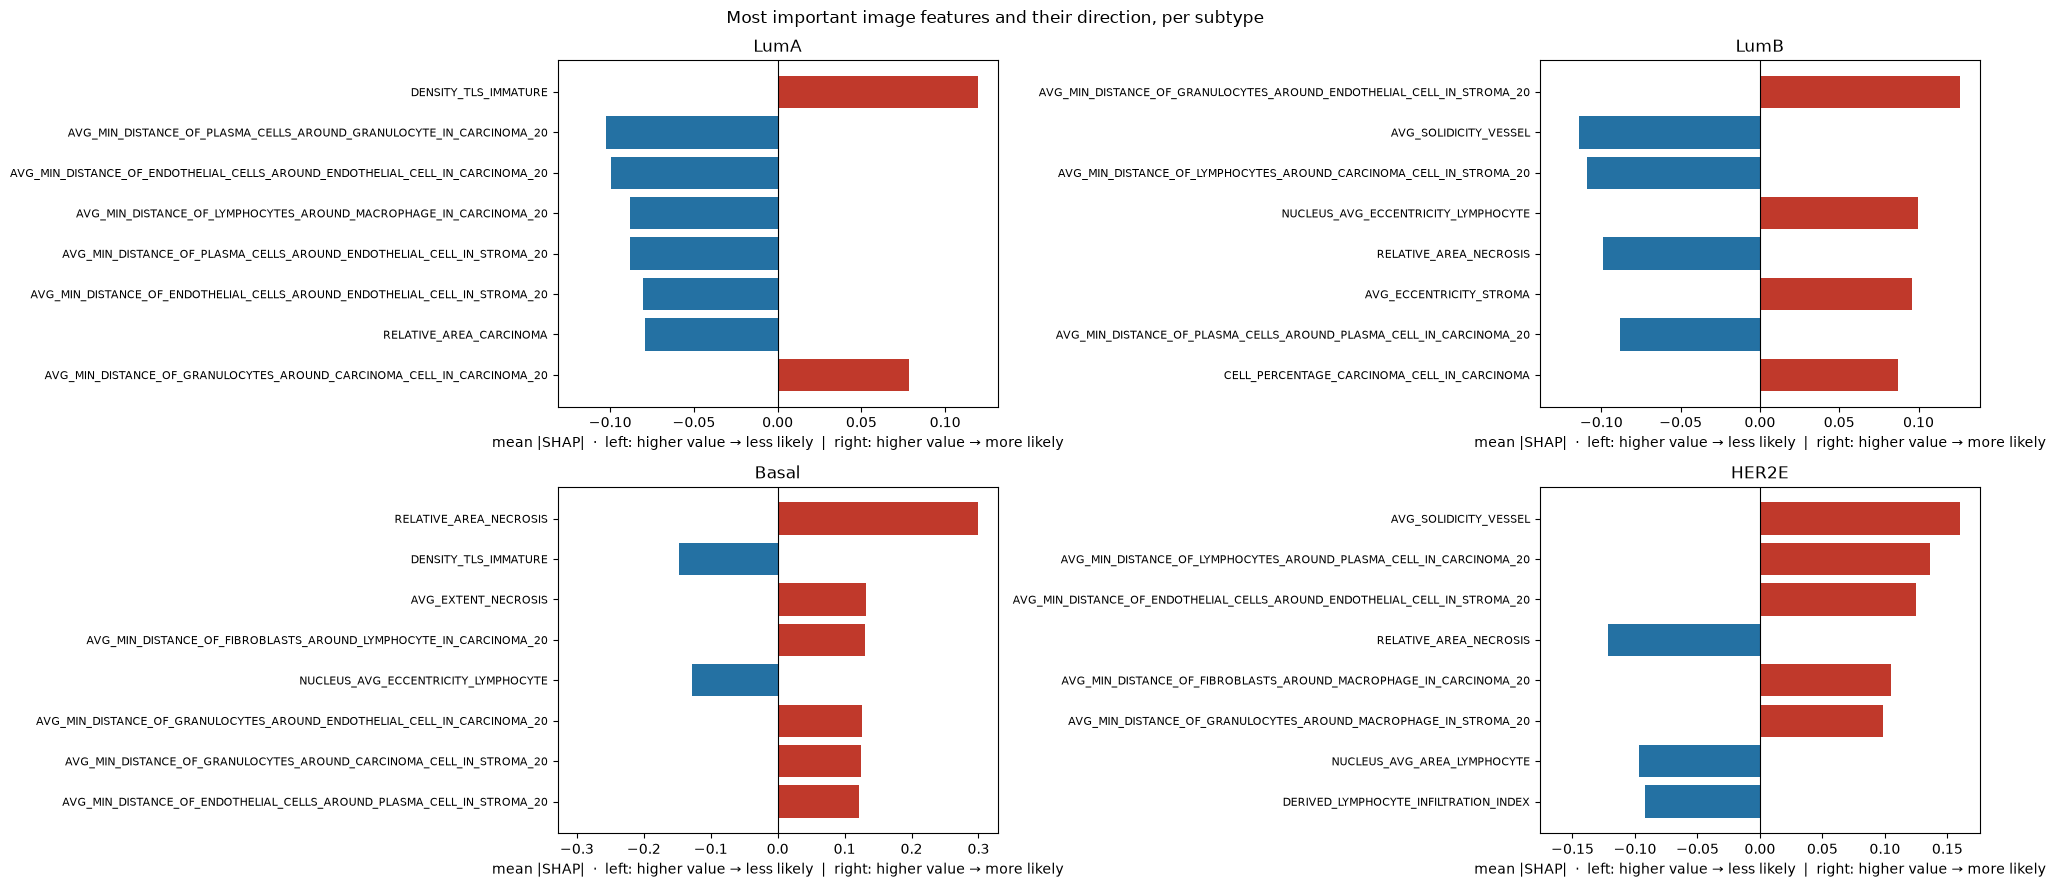

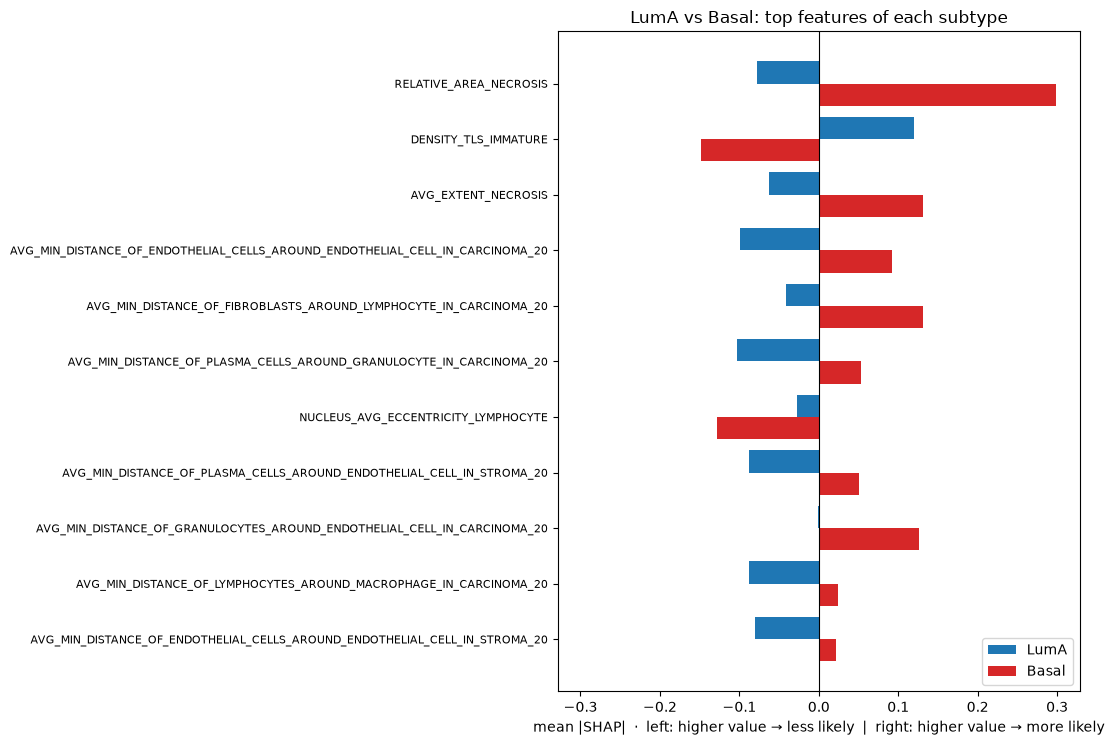

In [19]:
# Exact SHAP values need the linear model: if another family was selected, its tuned logistic regression is explained
explained = best_models["logistic"]
if SELECTED != "logistic":
    print(f"Selected model: {SELECTED}; the tuned logistic regression is explained instead")
logit = explained.named_steps["model"]
names = gp.feature_names_out(explained)
X_t = pd.DataFrame(explained[:-1].transform(X_train), columns=names)

explainer = shap.LinearExplainer(logit, shap.maskers.Independent(X_t, max_samples=len(X_t)))
shap_values = explainer(X_t).values                       # patients x features x subtypes
order = list(encoder.inverse_transform(logit.classes_))   # subtype of each output column

importance = pd.DataFrame({s: np.abs(shap_values[:, :, order.index(s)]).mean(axis=0) for s in CLASSES}, index=names)
signed = pd.DataFrame({s: importance[s] * np.sign(logit.coef_[order.index(s)]) for s in CLASSES}, index=names)
signed.to_csv(OUT_DIR / "subtype_shap_signed_importance.csv")

fig = gp.plot_stacked_importance(importance, COLORS, GP["shap_top_stacked"], title="Most important image features")
fig.savefig(FIGS / "subtype_shap_stacked.png", bbox_inches="tight")
plt.show()

fig = gp.plot_signed_importance(signed, GP["shap_top_signed"],
                                title="Most important image features and their direction, per subtype")
fig.savefig(FIGS / "subtype_shap_signed.png", bbox_inches="tight")
plt.show()

if GP["shap_pair"]:
    a, b = GP["shap_pair"]
    fig = gp.plot_pair_importance(signed, [a, b], COLORS, title=f"{a} vs {b}: top features of each subtype")
    fig.savefig(FIGS / f"subtype_shap_{a}_vs_{b}.png", bbox_inches="tight")
    plt.show()

**Observations (breast)**
- The model separates subtypes mainly through necrosis, which points to basal-like, and immune context (immature TLS, plasma-cell and lymphocyte neighbourhoods); immature TLS point to luminal A and away from basal-like.
- Vessel shape (solidity) is among the top features for luminal B and HER2-enriched tumours, although removing vessel features does not change performance (section 4.7): its information is shared with correlated features.
- Tumour-cell nuclear features are not among the most important; the difference in proliferation between luminal A and B would need features OpenTME does not yet include (e.g. mitotic counts).

tls_class,No TLS,Immature only,Mature
clin_pam50,,,
LumA,17.1,71.0,11.9
LumB,22.4,57.9,19.6
Basal,15.3,46.0,38.6
HER2E,9.1,54.5,36.4


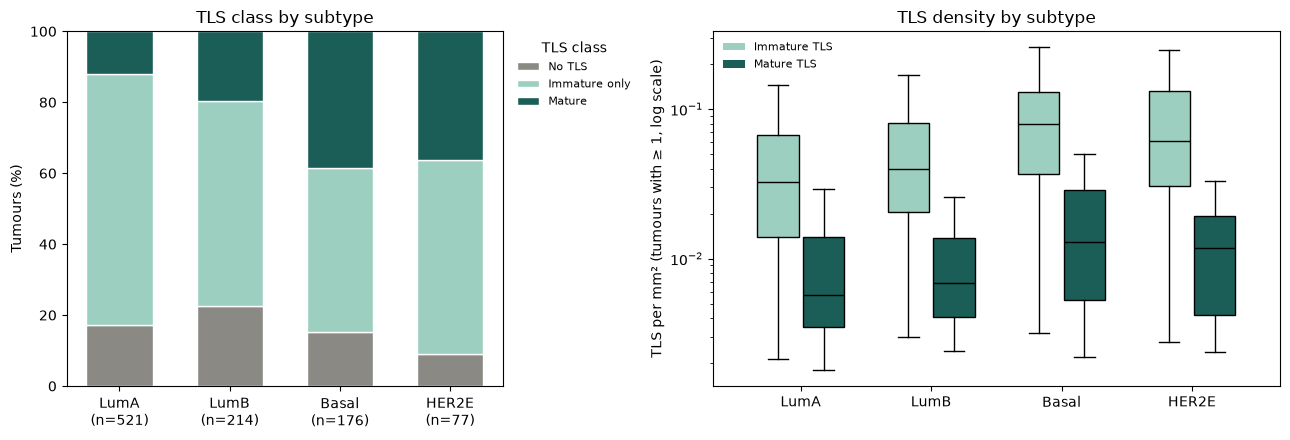

In [20]:
# Raw association (no model): TLS class and TLS densities by subtype, all tumours with a subtype
TLS_IMG = cfg["tls_analysis"]["image"]
TLS_FACTOR = cfg["density_per_mm2"]["tls"]               # unit factor of OpenTME TLS densities (to per mm²)
tls = d_sub[[SUBTYPE]].copy()
tls["tls_class"] = ph.tls_class(d_sub[TLS_IMG["present"]], d_sub[TLS_IMG["mature_present"]])
tls["Immature"] = d_sub[TLS_IMG["density_immature"]] * TLS_FACTOR
tls["Mature"] = d_sub[TLS_IMG["density_mature"]] * TLS_FACTOR

pct = (pd.crosstab(tls[SUBTYPE], tls["tls_class"], normalize="index") * 100).reindex(index=CLASSES, columns=ph.TLS_CLASSES)
n = tls[SUBTYPE].value_counts().reindex(CLASSES)
display(pct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
bottom = np.zeros(len(pct))
for c in ph.TLS_CLASSES:
    ax.bar(range(len(pct)), pct[c], bottom=bottom, color=TLS_GROUP_COLORS[c], label=c, width=0.6, edgecolor="white")
    bottom += pct[c].fillna(0).values
ax.set_xticks(range(len(pct)), [f"{s}\n(n={n[s]})" for s in CLASSES])
ax.set_ylabel("Tumours (%)")
ax.set_ylim(0, 100)
ax.set_title("TLS class by subtype")
ax.legend(title="TLS class", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)

# Densities among tumours with at least one TLS of that kind (log scale); zeros are summarised in panel A
ax = axes[1]
width = 0.35
for k, (kind, color) in enumerate(TLS_MATURITY_COLORS.items()):
    values = [tls.loc[(tls[SUBTYPE] == s) & (tls[kind] > 0), kind] for s in CLASSES]
    positions = np.arange(len(CLASSES)) + (k - 0.5) * width
    box = ax.boxplot(values, positions=positions, widths=width * 0.9, patch_artist=True, showfliers=False,
                     medianprops={"color": "black"})
    for patch in box["boxes"]:
        patch.set_facecolor(color)
    ax.bar(0, 0, color=color, label=f"{kind} TLS")       # legend entry
ax.set_yscale("log")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_ylabel("TLS per mm² (tumours with ≥ 1, log scale)")
ax.set_title("TLS density by subtype")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "subtype_tls_by_subtype.png", bbox_inches="tight")
plt.show()

**Observations (breast)**
- Any TLS is found in most tumours of every subtype (78–91 %); what differs is maturation: mature TLS in 12 % of luminal A, 20 % of luminal B and over a third of basal-like and HER2-enriched tumours, which also have higher densities of both immature and mature TLS.
- Luminal A tumours most often have immature TLS only (71 %), consistent with the SHAP direction (conditional on the other immune features) and with notebook 05, where maturation was associated with mutational burden, HRD and proliferation.

In [21]:
# Check: does the effect of immature TLS (LumA vs Basal) change sign when the immune context is added?
IMM = cfg["tls_analysis"]["image"]["density_immature"]
MAT = cfg["tls_analysis"]["image"]["density_mature"]
lb = sub_train[sub_train[SUBTYPE].isin(["LumA", "Basal"])]
y_lb = (lb[SUBTYPE] == "Basal").astype(int)                      # 1 = Basal, 0 = LumA
immune = [f for f in FEATURES if ("PLASMA" in f or "LYMPHOCYTE" in f) and f not in (IMM, MAT)]
feature_sets = {
    "1. immature TLS only": [IMM],
    "2. + mature TLS": [IMM, MAT],
    f"3. + plasma cell and lymphocyte features ({len(immune)})": [IMM, MAT] + immune,
    f"4. all image features ({len(FEATURES)})": FEATURES,
}
C = best_models["logistic"].named_steps["model"].C                 # same regularisation as the selected model
rows = []
for name, cols in feature_sets.items():
    model = Pipeline([("preprocess", gp.make_preprocessor()),
                      ("model", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])
    model.fit(lb[cols], y_lb)
    coef = dict(zip(gp.feature_names_out(model), model.named_steps["model"].coef_[0]))[IMM]
    rows.append({"model": name, "coefficient of immature TLS": coef, "direction": "→ Basal" if coef > 0 else "→ LumA"})
display(pd.DataFrame(rows).round(3))

/Users/Admin/Desktop/GitHub/opentme-tcga-integration/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (500) is greater than the total number of samples (475). n_quantiles is set to n_samples.
  warnings.warn(
/Users/Admin/Desktop/GitHub/opentme-tcga-integration/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (500) is greater than the total number of samples (475). n_quantiles is set to n_samples.
  warnings.warn(
/Users/Admin/Desktop/GitHub/opentme-tcga-integration/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (500) is greater than the total number of samples (475). n_quantiles is set to n_samples.
  warnings.warn(
/Users/Admin/Desktop/GitHub/opentme-tcga-integration/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_data.py:2912: UserWarning: n_quantiles (500) is greater than the total number of samples (475). n_quantiles is set to 

,model,coefficient of immature TLS,direction
0,1. immature TLS only,0.074,→ Basal
1,2. + mature TLS,-0.020,→ LumA
2,3. + plasma cell and lymphocyte features (101),-0.155,→ LumA
3,4. all image features (275),-0.077,→ LumA


**Observations (breast)**
- The coefficient of immature TLS density (luminal A vs basal-like) is positive on its own (+0.07, as in the raw comparison), close to zero once mature TLS are added (−0.02) and negative with the plasma-cell and lymphocyte features (−0.16) and with all features (−0.08), as in the SHAP values. Its SHAP direction is conditional: at a similar mature-TLS and immune context, TLS that form but do not mature point to luminal A.

The coefficient of immature TLS density (LumA vs basal-like) is positive on its own (+0.07, as in the raw comparison), close to zero once mature TLS are added and negative with the plasma-cell and lymphocyte features (−0.12) and with all features (−0.06), as in the SHAP values. Its SHAP direction is therefore conditional: at a similar mature-TLS and immune context, TLS that form but do not mature point to luminal A.

### 4.9 Final evaluation on the held-out sites

The test sites have not been used for any decision so far. The selected model, fitted on all training patients, predicts the subtype of the test patients once. Uncertainty of the macro one-vs-rest AUC is estimated by a bootstrap over test patients (`n_boot` resamples, 95 % interval). Similar values in cross-validation and on the test sites indicate that site-grouped cross-validation was not optimistic.

Test AUC (macro, one-vs-rest): 0.854 [95% CI 0.819–0.889] | F1 macro 0.630 | n = 287 patients, 8 sites


,n_test,auc_vs_rest
LumA,171,0.885
LumB,45,0.703
Basal,51,0.913
HER2E,20,0.916


              precision    recall  f1-score   support

        LumA       0.86      0.80      0.82       171
        LumB       0.31      0.36      0.33        45
       Basal       0.70      0.76      0.73        51
       HER2E       0.62      0.65      0.63        20

    accuracy                           0.71       287
   macro avg       0.62      0.64      0.63       287
weighted avg       0.73      0.71      0.72       287



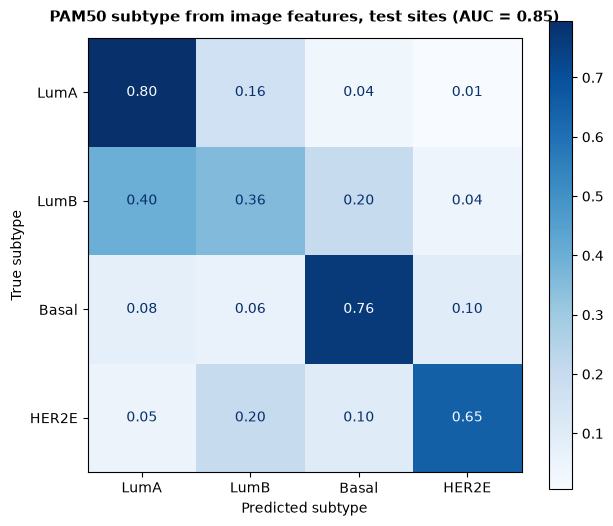

In [22]:
fitted = best_models[SELECTED]                            # refitted on all training patients
X_test, y_test = sub_test[FEATURES], encoder.transform(sub_test[SUBTYPE])
classes_num = list(fitted.classes_)
proba = fitted.predict_proba(X_test)
pred = fitted.predict(X_test)

macro_auc = lambda y, p: roc_auc_score(y, p, multi_class="ovr", average="macro", labels=classes_num)
auc_test = macro_auc(y_test, proba)
low, high = gp.bootstrap_ci(y_test, proba, macro_auc, n_boot=GP["n_boot"], seed=SEED, n_classes=len(classes_num))
print(f"Test AUC (macro, one-vs-rest): {auc_test:.3f} [95% CI {low:.3f}–{high:.3f}] | "
      f"F1 macro {f1_score(y_test, pred, average='macro'):.3f} | n = {len(y_test)} patients, {len(test_sites)} sites")

per_subtype = pd.DataFrame({
    "n_test": [int((y_test == c).sum()) for c in classes_num],
    "auc_vs_rest": [roc_auc_score(y_test == c, proba[:, k]) for k, c in enumerate(classes_num)],
}, index=encoder.inverse_transform(classes_num)).loc[CLASSES]
display(per_subtype.round(3))
print(classification_report(encoder.inverse_transform(y_test), encoder.inverse_transform(pred), labels=CLASSES,
                            zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(encoder.inverse_transform(y_test), encoder.inverse_transform(pred),
                                        labels=CLASSES, normalize="true", values_format=".2f", cmap="Blues", ax=ax)
ax.set_title(f"{SUBTYPE_LABEL} from image features, test sites (AUC = {auc_test:.2f})", fontsize=11,
             fontweight="bold", pad=12)
ax.set_xlabel("Predicted subtype")
ax.set_ylabel("True subtype")
fig.tight_layout()
fig.savefig(FIGS / "subtype_test_confusion.png", bbox_inches="tight")
plt.show()

pd.DataFrame([{"test_auc": auc_test, "ci_low": low, "ci_high": high, "n_test": len(y_test)}]).to_csv(
    OUT_DIR / "subtype_test_summary.csv", index=False)
per_subtype.to_csv(OUT_DIR / "subtype_test_per_subtype.csv")

**Observations (breast)**
- On the held-out sites the selected model reaches AUC 0.85 (95% CI 0.82–0.89), as in cross-validation: performance transfers to unseen hospitals.
- Per subtype (one-vs-rest AUC): basal-like 0.91, luminal A 0.89, HER2-enriched 0.92 (only 20 test patients) and luminal B 0.70, the hardest, confused mainly with luminal A.